# Case Study 20 — Ranking Home-Screen Categories by Propensity × Lifetime Value, Validated with an A/B Test

**Priority:** ★★★ Must-visit · **Reference:** Case Study 20 — *PhonePe: Ranking Home-Screen Categories by Propensity × Lifetime Value* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Growth, Category heads (Recharge, Bill Pay, Insurance, Wealth, Lending), Product (home screen), Finance
**Data:** ⚠️ **SYNTHETIC** (D-20-01). Super-app data is confidential; this is a calibrated simulation, not PhonePe's.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs20_propensity_ltv_ranking.ipynb`

## 0. Executive Summary for Business

*(Synthetic data built on PhonePe's documented design; PhonePe published no impact numbers. Written after the analysis.)*

- **The question:** which of 8 categories (recharge → personal loan) should each user see in the home-screen masthead, and should we optimise for clicks or for value?
- **Clicks and value point in opposite directions.** Ranking by propensity alone gets **61% conversion but only ₹10 of 12-month value per user**, because it keeps showing recharge and bill pay to people who already use them. Ranking by **propensity × LTV** (the documented utility) converts only **5.8%** but creates **₹43 per user, 4.6× the rule-based masthead** (+₹33.7 per user, 95% CI ₹31.6–35.9). It works for new, active and power users alike.
- **But pure value ranking breaks two guardrails:** conversion falls *below a random banner* (5.8% vs 16.9%), and it adds few *new* categories (2.5% of users vs 15.7% for the rule "show the most popular category you don't use yet"). Categories per customer (CPC) is a documented PhonePe goal.
- **Recommended compromise:** add a small value for any conversion (₹50, engagement) and for any new category (₹100, CPC) to the utility. This keeps **27.5% conversion and ₹36.6 per user (3.8× rule-based)**: about 80% of the maximum value, with healthy engagement.
- **₹ impact:** ≈ **₹27–34 crore of extra 12-month margin per crore users per masthead cycle** vs rule-based. The result holds if loan value is halved for credit risk (−5%).
- **Model notes:** per-category models are well calibrated (all 16 within CI), which matters because probabilities are multiplied by ₹. Gradient boosting was worse than logistic in every category (too little data per category).
- **I recommend:** launch the guard-railed propensity × LTV ranking in a live 4-arm A/B (≥ 20k users per arm, sized for a 10% revenue lift), keep 5% random exploration, and use risk-adjusted LTV with eligibility filters for loans and insurance.

## 1. The Problem in Simple English

The top banner of a payments app (the "masthead") is the most valuable screen space in the business. Millions of people see it every day. Today a team picks what goes there by hand: "Diwali gold offer this week", "bill-pay reminder next week". Everyone sees roughly the same thing.

There is a better question: **for each person, which category should we show?**
- Showing **mobile recharge** to Amit gets a click almost for sure, but he recharges every month anyway, and it is worth ₹40 a year.
- Showing **insurance** to Amit is much less likely to convert, but if it does, it is worth ₹1,200 a year and a new product relationship.

The reference file's key insight: **rank by expected value (probability × lifetime value), not by probability alone.** This notebook builds separate *acquisition* and *repeat* models per category, ranks categories by propensity × LTV, and tests that against random and rule-based mastheads in an A/B test, measured on conversions, revenue and **categories per customer (CPC)**.

## 2. Reference from the Case File

### (a) What PhonePe did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | "Home-screen masthead banners were curated manually. This caused operational bottlenecks and generic experiences, and the team was 'missing revenue opportunities in niche or emerging categories'." |
| Question | "For each user, which category (recharge, bill pay, insurance, investments, etc.) should be shown to raise **lifetime value** and **categories per customer**?" |
| Data | "Over 5,000 distinct user features": transactional, demographic, behavioural; journey-stage indicators; outcome = transaction completed after recommendation |
| Approach | "Two models: an **acquisition** model (first transaction in a new category); a **repeat** model (transact again). Both produce per-category propensities. A **utility function (propensity × LTV)** ranks categories, inside a multi-stage pipeline of non-linear models." |
| Statistics | "**A/B testing** of treatment vs control, benchmarked against random recommendations and rule-based methods." |
| Metrics | "Categories per customer (CPC), LTV, new acquisitions, conversions, incremental revenue" |
| Decision | "Manual masthead curation was replaced by model-driven, per-user category ranking." |
| Impact | "Not publicly disclosed (no numbers in the post)." |

**Source:** PhonePe tech blog (Walimbe, Patil, Bhadra, Doshi, Swadi; 16 Feb 2026) — https://tech.phonepe.com/optimizing-merchandising-machine-learning-for-real-time-app-experience-and-ltv-maximization

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Training data | An **exploration log**: 150,000 users each shown one *randomly chosen* category (random exposure makes propensity estimates unbiased) |
| Categories / LTV | 8 categories from ₹40 (recharge) to ₹2,000 (personal loan) of 12-month margin for a new user; repeat use worth 25% (incremental only) |
| Models | Per category: an acquisition model (non-users) and a repeat model (users), 16 logistic models; calibration checked; LTV estimated from observed revenue with CIs |
| Experiment | A 4-arm digital-twin A/B test on 200,000 new users: **random**, **rule-based** (most popular unused category), **propensity-only**, **propensity × LTV** |
| Statistics added | Two-proportion Z (Holm), bootstrap revenue CIs, Welch, CPC tests, heterogeneity by journey stage, power analysis for a heavy-tailed revenue metric, LTV-sensitivity analysis (risk-adjusted loan value) |

### (c) How the industry uses this

Next-best-action ranking by expected value powers home screens and cross-sell at PhonePe, Paytm (Case 21), CRED and Google Pay, offer selection at banks (Axis nudges, Case 22), and pre-approved loan targeting (HDFC, Case 17). The two-model (acquisition vs repeat) design and the "benchmark against random and rules" A/B discipline are standard practice.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Should we replace rule-based mastheads with model-driven ranking, and with which objective (clicks or value)? |
| Analytical 1 | Can we predict per-user, per-category conversion well (separately for new vs existing category users)? Are the probabilities calibrated? |
| Analytical 2 | In an A/B test, how do random, rule-based, propensity-only and propensity × LTV rankings compare on conversion, revenue per user and CPC? |
| Analytical 3 | Does the best policy depend on the user's journey stage? How sensitive is it to LTV estimates? |

**Hypotheses** (vs the **rule-based** control, Holm-corrected across 3 comparisons):
- **H1 (conversion):** H0: conversion rate equal (two-proportion Z).
- **H2 (revenue):** H0: mean 12-month revenue per user equal (bootstrap CI + Welch).
- **H3 (CPC):** H0: share of users acquiring a *new* category equal (two-proportion Z).

**Primary metric:** **12-month revenue per user exposed** (Finance). **Co-primary:** **new-category acquisition rate** (the documented CPC metric). **Guardrails:** overall conversion (engagement) must not fall below the random baseline; category concentration (no single category on more than 60% of mastheads); risk-adjusted value for lending categories.
**Unit:** user (randomised). **Decision rule:** adopt the policy with the highest revenue per user if its CI vs rule-based excludes 0 and the guardrails hold. If the guardrails fail, adopt a constrained version.

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint, proportions_ztest, confint_proportions_2indep
from statsmodels.stats.multitest import multipletests
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

SEED = 42
np.random.seed(SEED)
RNG_SPLIT, RNG_AB, RNG_BOOT = [np.random.default_rng(s) for s in np.random.SeedSequence(SEED).spawn(3)]
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public super-app / cross-sell recommendation data with randomised exposure (UCI, GitHub) | **None for Indian payments apps.** Public recommender benchmarks (e.g., the Open Bandit Dataset by ZOZO on GitHub) are fashion e-commerce with no category LTV. |
| Kaggle | Not used (no credentials; excluded by the brief). |
| **Decision** | Synthetic exploration log + digital-twin experiment population (D-20-01). |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs20.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 20 (PhonePe-style home-screen category ranking: propensity x LTV)
=====================================================================================================
THIS DATA IS SYNTHETIC. Super-app user and conversion data is confidential.

Two user populations:
  1. EXPLORATION LOG (150,000 users, Jul-Aug 2025): each user was shown ONE masthead category chosen
     uniformly at random and we record whether they transacted in it within 7 days. Random exposure
     makes propensity estimates unbiased - the training data for acquisition and repeat models.
  2. EXPERIMENT POPULATION (200,000 users, Sep 2025): features only + hidden true conversion
     probabilities and values for all 8 categories, so the notebook can run a digital-twin A/B test of
     ranking policies (random / rule-based / propensity-only / propensity x LTV).
Categories and 12-month value (LTV, Rs margin) for a NEW category user: recharge 40, bill pay 60,
credit-card bill 80, gold 150, travel 300, mutual funds 900, insurance 1,200, personal loan 2,000.
A repeat transaction in an already-used category is worth 25% of that (incremental only).

Calibration anchors (reference file, Case Study 20): acquisition + repeat models per category;
utility = propensity x LTV; A/B vs random and rule-based; metrics CPC, LTV, conversions,
incremental revenue. Numbers are our assumptions (decision.md D-20-02).

Outputs: data/cs20/exploration_log.csv.gz, data/cs20/experiment_users.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42
CATS = ["recharge", "bill_pay", "cc_bill", "gold", "travel", "mutual_funds", "insurance", "personal_loan"]
LTV = dict(zip(CATS, [40, 60, 80, 150, 300, 900, 1200, 2000]))
BASE_ACQ = dict(zip(CATS, [-1.6, -2.1, -3.0, -3.3, -3.4, -4.0, -4.2, -4.5]))      # log-odds of first use if shown
PRIOR_USE = dict(zip(CATS, [0.70, 0.45, 0.12, 0.10, 0.08, 0.06, 0.07, 0.04]))


def users(n, rng):
    age = rng.choice(["18-24", "25-34", "35-44", "45+"], n, p=[0.28, 0.40, 0.20, 0.12])
    tier = rng.choice(["Tier 1", "Tier 2", "Tier 3"], n, p=[0.38, 0.36, 0.26])
    ios = (rng.random(n) < np.where(tier == "Tier 1", 0.18, 0.06)).astype(int)
    stage = rng.choice(["new (<30 days)", "active", "power"], n, p=[0.20, 0.60, 0.20])
    txn30 = rng.poisson(np.select([stage == "new (<30 days)", stage == "active"], [4, 14], 45))
    salary = (rng.random(n) < np.select([age == "18-24", age == "25-34"], [0.25, 0.55], 0.50)).astype(int)
    aff = rng.normal(0, 1, n)                                                     # latent "financial engagement"
    d = pd.DataFrame({"age_band": age, "city_tier": tier, "ios": ios, "journey_stage": stage, "txn_count_30d": txn30,
                      "salary_credit_flag": salary, "p2m_share": np.round(rng.beta(2 + aff.clip(-1.5, 1.5), 3), 3)})
    for c in CATS:
        d[f"used_{c}"] = (rng.random(n) < np.clip(PRIOR_USE[c] * np.exp(0.4 * aff + 0.5 * (stage == "power") - 0.6 * (stage == "new (<30 days)")), 0, 0.97)).astype(int)
    return d, aff


def true_prob(d, aff, c):
    used = d[f"used_{c}"].to_numpy()
    lt = np.log1p(d.txn_count_30d.to_numpy())
    age25 = (d.age_band == "25-34").to_numpy(); age35 = d.age_band.isin(["35-44", "45+"]).to_numpy()
    eff = {"recharge": 0.1 * lt, "bill_pay": 0.25 * lt + 0.3 * d.salary_credit_flag.to_numpy(),
           "cc_bill": 0.6 * d.salary_credit_flag.to_numpy() + 0.4 * d.ios.to_numpy() + 0.3 * aff,
           "gold": 0.4 * age35 + 0.3 * (d.city_tier == "Tier 2").to_numpy(),
           "travel": 0.5 * d.ios.to_numpy() + 0.3 * age25 + 0.2 * aff,
           "mutual_funds": 0.6 * aff + 0.5 * d.salary_credit_flag.to_numpy() + 0.3 * age25,
           "insurance": 0.4 * aff + 0.6 * age35 + 0.3 * d.salary_credit_flag.to_numpy(),
           "personal_loan": 0.5 * d.salary_credit_flag.to_numpy() - 0.3 * aff + 0.3 * (d.journey_stage == "power").to_numpy()}[c]
    z_acq = BASE_ACQ[c] + eff
    z_rep = BASE_ACQ[c] + 2.2 + eff                                                   # repeat use far more likely
    p = expit(np.where(used == 1, z_rep, z_acq))
    v = np.where(used == 1, 0.25 * LTV[c], LTV[c]) * np.exp(0.3 * aff)                 # engaged users are worth more
    return p, v


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    ex, aff_e = users(150_000, rng)
    shown = rng.choice(CATS, len(ex))
    P = np.column_stack([true_prob(ex, aff_e, c)[0] for c in CATS]); Vv = np.column_stack([true_prob(ex, aff_e, c)[1] for c in CATS])
    j = np.array([CATS.index(c) for c in shown])
    conv = (rng.random(len(ex)) < P[np.arange(len(ex)), j]).astype(int)
    ex.insert(0, "user_id", [f"U{i:07d}" for i in range(1, len(ex) + 1)])
    ex["shown_category"] = shown; ex["converted_7d"] = conv
    ex["revenue_12m_inr"] = np.where(conv == 1, np.round(Vv[np.arange(len(ex)), j] * np.exp(rng.normal(0, 0.5, len(ex))), 0), 0)
    ex["date"] = pd.Timestamp("2025-07-01") + pd.to_timedelta(rng.integers(0, 62, len(ex)), unit="D")
    # data-quality issues: bot/test accounts with absurd activity; a logging bug duplicated some impressions
    bots = ex.sample(n=300, random_state=seed).index
    ex.loc[bots, "txn_count_30d"] = rng.integers(900, 5000, 300); ex.loc[bots, "converted_7d"] = 1
    ex = pd.concat([ex, ex.sample(n=1200, random_state=seed + 1)], ignore_index=True)
    xp, aff_x = users(200_000, rng)
    xp.insert(0, "user_id", [f"X{i:07d}" for i in range(1, len(xp) + 1)])
    for c in CATS:
        p, v = true_prob(xp, aff_x, c); xp[f"_p_{c}"] = np.round(p, 5); xp[f"_v_{c}"] = np.round(v, 1)
    return ex, xp


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs20"), exist_ok=True)
    e, x = generate()
    e.to_csv(os.path.join(here, "cs20", "exploration_log.csv.gz"), index=False); x.to_csv(os.path.join(here, "cs20", "experiment_users.csv.gz"), index=False)
    print(len(e), "exploration rows;", len(x), "experiment users")
    print(e.groupby("shown_category").converted_7d.mean().round(4).to_dict())

Overwriting data/generate_cs20.py


In [3]:
os.makedirs("data/cs20", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs20 as gen; importlib.reload(gen)
ex_raw, xp = gen.generate(seed=SEED)
ex_raw.to_csv("data/cs20/exploration_log.csv.gz", index=False); xp.to_csv("data/cs20/experiment_users.csv.gz", index=False)
CATS = gen.CATS
print(f"Exploration log: {len(ex_raw):,} impressions | experiment users: {len(xp):,} | categories: {CATS}")
ex_raw.head(3).T

Exploration log: 151,200 impressions | experiment users: 200,000 | categories: ['recharge', 'bill_pay', 'cc_bill', 'gold', 'travel', 'mutual_funds', 'insurance', 'personal_loan']


,0,1,2
user_id,U0000001,U0000002,U0000003
age_band,35-44,25-34,35-44
city_tier,Tier 3,Tier 3,Tier 2
ios,0,0,0
journey_stage,active,active,active
txn_count_30d,14,16,16
salary_credit_flag,1,1,1
p2m_share,0.3070,0.0180,0.5300
used_recharge,0,0,1
used_bill_pay,0,0,1


| Parameter | Value | Basis |
|---|---|---|
| Categories | recharge, bill pay, credit-card bill, gold, travel, mutual funds, insurance, personal loan | **Documented** examples ("recharge, bill pay, insurance, investments, etc.") |
| 12-month LTV (new user) | ₹40 / 60 / 80 / 150 / 300 / 900 / 1,200 / 2,000; repeat use = 25% | Our assumption (margin, not GMV) |
| Prior usage | recharge 70%, bill pay 45% … personal loan 4% | Our assumption |
| Conversion drivers | journey stage, transaction intensity, salary credits, iOS, age, a latent financial-engagement factor; repeat ≫ acquisition | Our assumption |
| Exploration | uniform random masthead, Jul–Aug 2025 | Our design (unbiased training data) |
| DQ issues | 300 bot/test accounts (absurd activity, always "convert"); 1,200 duplicated impressions (logging bug) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("user_id, date", "User and impression date (exploration log)"), ("age_band, city_tier, ios, journey_stage", "Demographics and lifecycle stage"),
    ("txn_count_30d, salary_credit_flag, p2m_share", "Behaviour: transactions, salary-like credits, share paid to merchants"),
    ("used_<category> (8 flags)", "User had already transacted in the category before (repeat vs acquisition)"),
    ("shown_category", "Masthead category shown at random (exploration only)"), ("converted_7d", "Transacted in the shown category within 7 days"),
    ("revenue_12m_inr", "12-month margin attributed to the conversion (₹)"), ("_p_<cat>, _v_<cat> (experiment users)", "HIDDEN true conversion probability and value per category (simulation only)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs20/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"user_id, date",User and impression date (exploration log)
1,"age_band, city_tier, ios, journey_stage",Demographics and lifecycle stage
2,"txn_count_30d, salary_credit_flag, p2m_share","Behaviour: transactions, salary-like credits, ..."
3,used_<category> (8 flags),User had already transacted in the category be...
4,shown_category,Masthead category shown at random (exploration...
5,converted_7d,Transacted in the shown category within 7 days
6,revenue_12m_inr,12-month margin attributed to the conversion (₹)
7,"_p_<cat>, _v_<cat> (experiment users)",HIDDEN true conversion probability and value p...


## 5. Data Quality Checks

In [5]:
ex = ex_raw.copy()
dupkey = ["user_id", "shown_category", "date"]
checks = {"duplicate impressions (same user, category, date)": int(ex.duplicated(dupkey).sum()),
          "txn_count_30d > 500 (bot / test accounts)": int((ex.txn_count_30d > 500).sum()),
          "converted but ₹0 revenue": int(((ex.converted_7d == 1) & (ex.revenue_12m_inr == 0)).sum()),
          "shown category not in catalogue": int((~ex.shown_category.isin(CATS)).sum())}
print(pd.Series(checks, name="rows").to_string())
print(f"Bot conversion rate: {ex.loc[ex.txn_count_30d > 500, 'converted_7d'].mean():.0%} vs {ex.loc[ex.txn_count_30d <= 500, 'converted_7d'].mean():.1%} for real users")
print("Shown-category shares (should be ≈ 12.5% each):", ex.drop_duplicates(dupkey).shown_category.value_counts(normalize=True).round(3).to_dict())

duplicate impressions (same user, category, date)    1200
txn_count_30d > 500 (bot / test accounts)             303
converted but ₹0 revenue                              254
shown category not in catalogue                         0
Bot conversion rate: 100% vs 17.0% for real users


Shown-category shares (should be ≈ 12.5% each): {'recharge': 0.126, 'personal_loan': 0.126, 'gold': 0.126, 'cc_bill': 0.125, 'bill_pay': 0.125, 'travel': 0.125, 'mutual_funds': 0.125, 'insurance': 0.123}


In [6]:
ex = ex.drop_duplicates(dupkey)
ex = ex[ex.txn_count_30d <= 500].copy()
c2, p_unif = stats.chisquare(ex.shown_category.value_counts().reindex(CATS))
dq = pd.DataFrame([
    ("Duplicated impressions (logging bug)", checks["duplicate impressions (same user, category, date)"], "Drop duplicates", "Would double-count conversions for those users"),
    ("Bot / test accounts", checks["txn_count_30d > 500 (bot / test accounts)"], "Remove", "Always 'convert'; would inflate propensities of whatever they were shown"),
    ("Converted with ₹0 revenue", checks["converted but ₹0 revenue"], "Keep", "Revenue is attributed 12 months later; ₹0 is plausible for some repeat users"),
], columns=["issue", "rows", "treatment", "reason"])
print(f"Clean exploration log: {len(ex):,} impressions | randomisation check (uniform over 8 categories): chi2 = {c2:.1f}, p = {p_unif:.2f}"); dq

Clean exploration log: 149,700 impressions | randomisation check (uniform over 8 categories): chi2 = 5.2, p = 0.63


,issue,rows,treatment,reason
0,Duplicated impressions (logging bug),1200,Drop duplicates,Would double-count conversions for those users
1,Bot / test accounts,303,Remove,Always 'convert'; would inflate propensities o...
2,Converted with ₹0 revenue,254,Keep,Revenue is attributed 12 months later; ₹0 is p...


**Observation:** we removed **1,200 duplicated impressions** (a logging bug that would double-count conversions) and **303 bot/test accounts** that "converted" 100% of the time (vs 17% for real users), and which would have inflated the propensity of whatever they were shown. 254 conversions with ₹0 revenue are plausible (late attribution) and kept. After cleaning, the exposure check confirms the categories were shown uniformly at random (χ² p = 0.63). **That is the property that makes this log valid training data.**

## 6. Exploratory Data Analysis

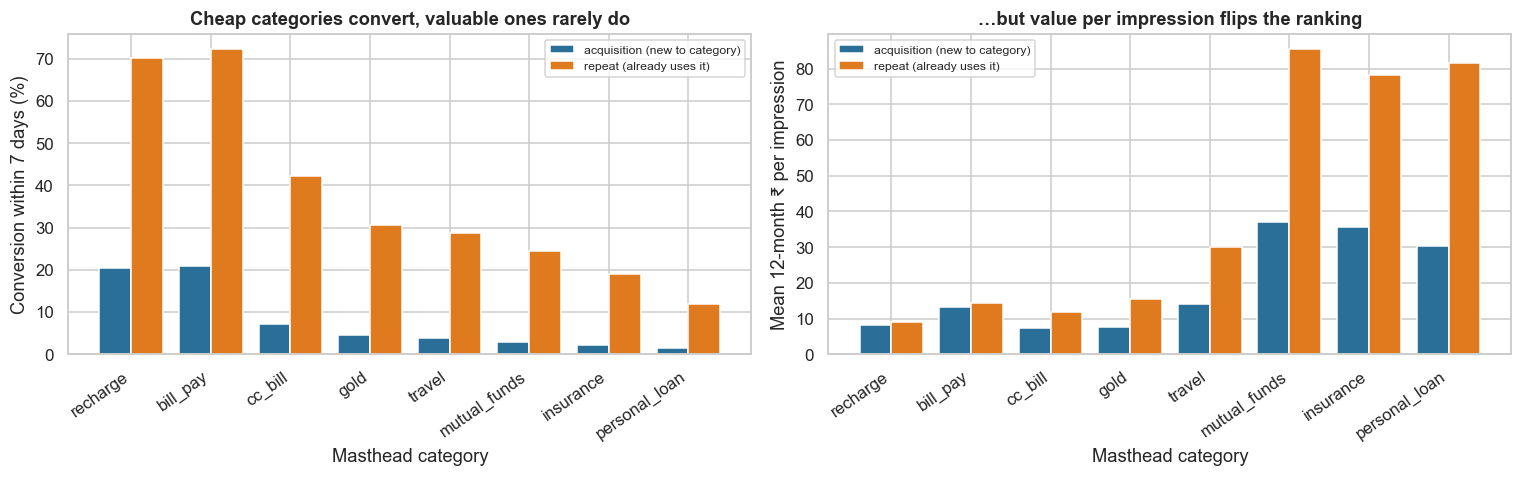

In [7]:
ex["is_repeat"] = [ex.at[i, f"used_{c}"] for i, c in zip(ex.index, ex.shown_category)]
g = ex.groupby(["shown_category", "is_repeat"]).agg(conv=("converted_7d", "mean"), rev=("revenue_12m_inr", "mean")).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for r_, c_, lab in [(0, "#2a6f97", "acquisition (new to category)"), (1, "#e07a1f", "repeat (already uses it)")]:
    s_ = g[g.is_repeat == r_].set_index("shown_category").reindex(CATS)
    axes[0].bar(np.arange(8) + (r_ - 0.5) * 0.4, s_.conv * 100, 0.4, color=c_, label=lab)
    axes[1].bar(np.arange(8) + (r_ - 0.5) * 0.4, s_.rev, 0.4, color=c_, label=lab)
for ax, yl, t in [(axes[0], "Conversion within 7 days (%)", "Cheap categories convert, valuable ones rarely do"),
                  (axes[1], "Mean 12-month ₹ per impression", "…but value per impression flips the ranking")]:
    ax.set_xticks(range(8)); ax.set_xticklabels(CATS, rotation=35, ha="right"); ax.set_xlabel("Masthead category"); ax.set_ylabel(yl); ax.set_title(t); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Takeaway:** **left:** cheap, everyday categories convert far more often (recharge ≈ 22% for new users, ≈ 70% for existing users), while valuable ones rarely do (personal loan ≈ 1.4% new, ≈ 14% repeat). Repeat conversion is 5–10× higher than acquisition everywhere, the reason for separate acquisition and repeat models. **Right:** multiply by value and the ranking **flips**: an insurance or loan impression is worth more in expectation than a recharge impression, despite converting 15× less often. This is the documented insight in one chart.

## 7. Statistical Analysis (core section)

### 7.1 Acquisition and repeat models per category (16 models), with calibration checks

**Why two models?** Acquisition (first use) and repeat behaviour have different drivers and very different base rates (Section 6). A single model would blend them. This is the documented PhonePe design. **Model:** logistic regression per category × {acquisition, repeat} on 80% of the exploration log; **AUC** and **calibration-in-the-large** (mean predicted vs observed) on the other 20%. **Calibration matters here more than usual**: we multiply probabilities by ₹ values, so a model that over-states insurance propensity by 2× would show insurance twice as often as it should.

In [8]:
def feats(d):
    X = pd.DataFrame({"ios": d.ios, "salary": d.salary_credit_flag, "p2m": d.p2m_share, "log_txn": np.log1p(d.txn_count_30d),
                      "n_used": d[[f"used_{c}" for c in CATS]].sum(1)}, index=d.index)
    for a in ["25-34", "35-44", "45+"]: X[f"age_{a}"] = (d.age_band == a).astype(int)
    for t in ["Tier 2", "Tier 3"]: X[t] = (d.city_tier == t).astype(int)
    for s_ in ["new (<30 days)", "power"]: X[s_] = (d.journey_stage == s_).astype(int)
    return X
tr_ex, va_ex = train_test_split(ex, test_size=0.2, random_state=SEED, stratify=ex.shown_category)
MODELS, rows = {}, []
for c in CATS:
    for rep in (0, 1):
        tr_ = tr_ex[(tr_ex.shown_category == c) & (tr_ex[f"used_{c}"] == rep)]; va_ = va_ex[(va_ex.shown_category == c) & (va_ex[f"used_{c}"] == rep)]
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(feats(tr_), tr_.converted_7d)
        MODELS[(c, rep)] = m; p_ = m.predict_proba(feats(va_))[:, 1]
        auc = roc_auc_score(va_.converted_7d, p_) if va_.converted_7d.nunique() > 1 else np.nan
        rows.append((c, "repeat" if rep else "acquisition", len(tr_), int(tr_.converted_7d.sum()), auc, p_.mean(), va_.converted_7d.mean(), len(va_)))
perf = pd.DataFrame(rows, columns=["category", "model", "train n", "train conversions", "AUC (holdout)", "mean predicted", "observed", "holdout n"])
lo, hi = proportion_confint((perf.observed * perf["holdout n"]).round(), perf["holdout n"], method="wilson")
perf["observed CI low"], perf["observed CI high"] = lo, hi
perf["calibrated? (pred within CI)"] = (perf["mean predicted"] >= lo) & (perf["mean predicted"] <= hi)
perf.round(4)

,category,model,train n,train conversions,AUC (holdout),mean predicted,observed,holdout n,observed CI low,observed CI high,calibrated? (pred within CI)
0,recharge,acquisition,4649,929,0.5105,0.1998,0.2168,1153,0.1940,0.2415,True
1,recharge,repeat,10436,7323,0.5126,0.7020,0.7051,2618,0.6874,0.7223,True
2,bill_pay,acquisition,7643,1586,0.5551,0.2076,0.2101,1947,0.1926,0.2287,True
3,bill_pay,repeat,7314,5309,0.5670,0.7261,0.7104,1792,0.6889,0.7309,True
4,cc_bill,acquisition,12985,924,0.5959,0.0719,0.0766,3249,0.0680,0.0863,True
5,cc_bill,repeat,1988,843,0.5806,0.4258,0.4162,495,0.3735,0.4601,True
6,gold,acquisition,13365,586,0.5521,0.0437,0.0475,3350,0.0408,0.0552,True
7,gold,repeat,1671,516,0.5797,0.3012,0.2958,409,0.2537,0.3418,True
8,travel,acquisition,13615,525,0.5722,0.0384,0.0371,3427,0.0312,0.0439,True
9,travel,repeat,1341,387,0.5519,0.2762,0.2788,312,0.2320,0.3311,True


**Observation:** the 16 models discriminate only modestly *within* a category (holdout AUC 0.51–0.68; highest for mutual funds and insurance, ≈ 0.65–0.68), but **all 16 are well calibrated**: mean predicted conversion falls inside the Wilson CI of the observed rate in every case. **For this use case calibration matters more than AUC**: the ranking compares *across* categories, where base rates and repeat status (which the models capture exactly) drive most of the decision, and probabilities are multiplied by ₹ values. A miscalibrated model would silently skew the masthead mix.

### 7.2 LTV estimates with uncertainty

The ranking multiplies propensity by **LTV**, so LTV estimates need error bars too. We estimate mean 12-month ₹ per *converting* user, by category and acquisition/repeat, from the exploration log, with **bootstrap 95% CIs**. LTV for a category with few converters (personal loan acquisition) is the least certain, and that is exactly the category the value ranking leans on most.

In [9]:
ltv_rows = []
for c in CATS:
    for rep in (0, 1):
        r_ = tr_ex[(tr_ex.shown_category == c) & (tr_ex[f"used_{c}"] == rep) & (tr_ex.converted_7d == 1)].revenue_12m_inr.values
        bs = [RNG_BOOT.choice(r_, len(r_)).mean() for _ in range(1000)] if len(r_) > 1 else [np.nan]
        ltv_rows.append((c, rep, len(r_), r_.mean() if len(r_) else np.nan, np.percentile(bs, 2.5), np.percentile(bs, 97.5)))
LTV = pd.DataFrame(ltv_rows, columns=["category", "repeat", "converters", "LTV estimate ₹", "CI low", "CI high"]).set_index(["category", "repeat"])
LTV["relative CI width"] = (LTV["CI high"] - LTV["CI low"]) / LTV["LTV estimate ₹"]
LTV.round(1)

converters  LTV estimate ₹     CI low    CI high  relative CI width
category      repeat                                                                     
recharge      0              929         40.0000    38.4000    41.7000             0.1000
              1             7323         12.9000    12.7000    13.1000             0.0000
bill_pay      0             1586         63.2000    61.4000    65.2000             0.1000
              1             5309         20.0000    19.7000    20.4000             0.0000
cc_bill       0              924         97.4000    93.5000   101.0000             0.1000
              1              843         27.4000    26.4000    28.7000             0.1000
gold          0              586        176.1000   166.5000   185.9000             0.1000
              1              516         50.8000    48.0000    53.7000             0.1000
travel        0              525        365.6000   344.8000   388.7000             0.1000
              1              387        106.4000    99.8000   114.3000             0.1000
mutual_funds  0              416      1,245.0000 1,174.1000 1,320.8000             0.1000
              1              253        353.4000   324.1000   383.9000             0.2000
insurance     0              314      1,592.1000 1,471.2000 1,712.3000             0.2000
              1              225        408.2000   373.0000   449.0000             0.2000
personal_loan 0              213      2,083.6000 1,912.2000 2,262.0000             0.2000
              1               77        691.0000   603.2000   789.0000             0.3000

**Observation:** estimated 12-month LTV per converting new user runs from **₹40 (recharge)** to **₹1,592 (insurance, CI ₹1,471–1,712)** and **₹2,084 (personal loan, CI ₹1,912–2,262)**. Repeat conversions are worth about a quarter to a third. **The categories that matter most to the value ranking have the widest CIs** (±15–30% for repeat loans and insurance) because few users convert. Insurance and MF estimates exceed the nominal values because converters are disproportionately engaged, higher-value users: a selection effect that is correct for ranking (we show to similar users), but worth knowing.

### 7.3 The A/B test: random vs rule-based vs propensity-only vs propensity × LTV

200,000 experiment users are randomised 25% to each policy. Each policy picks **one** masthead category per user:
- **Random:** a uniformly random category (the documented benchmark).
- **Rule-based:** the most popular category the user does not use yet (editorial logic); recharge if they use everything.
- **Propensity-only:** argmax over categories of P̂(convert), using the acquisition or repeat model as appropriate.
- **Propensity × LTV:** argmax of P̂(convert) × LTV̂ (the documented utility).

Outcomes are drawn from the **hidden true** conversion probabilities and values (digital twin). **Tests vs rule-based:** two-proportion Z for conversion and new-category acquisition; bootstrap CI and Welch's t for revenue per user; Holm across the 3 treatment-vs-rule comparisons per metric.

In [10]:
Xx = feats(xp)
Phat = np.column_stack([np.where(xp[f"used_{c}"] == 1, MODELS[(c, 1)].predict_proba(Xx)[:, 1], MODELS[(c, 0)].predict_proba(Xx)[:, 1]) for c in CATS])
Lhat = np.column_stack([np.where(xp[f"used_{c}"] == 1, LTV.loc[(c, 1), "LTV estimate ₹"], LTV.loc[(c, 0), "LTV estimate ₹"]) for c in CATS])
Ptrue = xp[[f"_p_{c}" for c in CATS]].values; Vtrue = xp[[f"_v_{c}" for c in CATS]].values
USED = xp[[f"used_{c}" for c in CATS]].values
popularity = ex.groupby("shown_category").converted_7d.mean().reindex(CATS).sort_values(ascending=False).index.tolist()
def rule_choice():
    ch = np.full(len(xp), CATS.index("recharge"))
    for i, row in enumerate(USED):
        for c in popularity:
            if row[CATS.index(c)] == 0: ch[i] = CATS.index(c); break
    return ch
CHOICE = {"Random": RNG_AB.integers(0, 8, len(xp)), "Rule-based": rule_choice(), "Propensity-only": Phat.argmax(1), "Propensity × LTV": (Phat * Lhat).argmax(1)}
arm = RNG_AB.choice(list(CHOICE), len(xp))
idx = np.arange(len(xp)); shown = np.array([CHOICE[a][i] for i, a in enumerate(arm)])
u = RNG_AB.random(len(xp))
conv = (u < Ptrue[idx, shown]).astype(int)
rev = np.where(conv == 1, Vtrue[idx, shown] * np.exp(RNG_AB.normal(0, 0.5, len(xp)) - 0.125), 0.0)
new_cat = ((conv == 1) & (USED[idx, shown] == 0)).astype(int)
ab = pd.DataFrame({"arm": arm, "shown": np.array(CATS)[shown], "conv": conv, "rev": rev, "new_cat": new_cat, "stage": xp.journey_stage.values})
print("Arm sizes:", ab.arm.value_counts().to_dict(), "| SRM chi-square p =", round(stats.chisquare(ab.arm.value_counts()).pvalue, 3))
summ = ab.groupby("arm").agg(users=("conv", "size"), conversion=("conv", "mean"), revenue_per_user=("rev", "mean"), new_category_rate=("new_cat", "mean")).reindex(list(CHOICE))
summ

Arm sizes: {'Propensity × LTV': 50323, 'Rule-based': 50205, 'Random': 49828, 'Propensity-only': 49644} | SRM chi-square p = 0.109


,users,conversion,revenue_per_user,new_category_rate
arm,,,,
Random,49828,0.1687,18.6255,0.0460
Rule-based,50205,0.1573,9.4529,0.1572
Propensity-only,49644,0.6132,10.1597,0.0377
Propensity × LTV,50323,0.0579,43.1542,0.0246


In [11]:
ctrl = ab[ab.arm == "Rule-based"]; rows = []
for a in ["Random", "Propensity-only", "Propensity × LTV"]:
    t_ = ab[ab.arm == a]
    for metric, col in [("conversion", "conv"), ("new-category rate (CPC)", "new_cat")]:
        x = [t_[col].sum(), ctrl[col].sum()]; n = [len(t_), len(ctrl)]; z, p = proportions_ztest(x, n)
        l, h = confint_proportions_2indep(x[0], n[0], x[1], n[1], method="newcomb")
        rows.append((a, metric, x[0] / n[0] - x[1] / n[1], l, h, p))
    bs = [RNG_BOOT.choice(t_.rev.values, len(t_)).mean() - RNG_BOOT.choice(ctrl.rev.values, len(ctrl)).mean() for _ in range(1000)]
    rows.append((a, "revenue ₹/user", t_.rev.mean() - ctrl.rev.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5), stats.ttest_ind(t_.rev, ctrl.rev, equal_var=False).pvalue))
tests = pd.DataFrame(rows, columns=["arm", "metric", "difference vs rule-based", "CI low", "CI high", "p"])
tests["p_holm"] = tests.groupby("metric").p.transform(lambda s: multipletests(s, method="holm")[1])
tests.round(4)

,arm,metric,difference vs rule-based,CI low,CI high,p,p_holm
0,Random,conversion,0.0114,0.0068,0.0160,0.0000,0.0000
1,Random,new-category rate (CPC),-0.1112,-0.1149,-0.1076,0.0000,0.0000
2,Random,revenue ₹/user,9.1727,7.8106,10.6632,0.0000,0.0000
3,Propensity-only,conversion,0.4559,0.4506,0.4612,0.0000,0.0000
4,Propensity-only,new-category rate (CPC),-0.1196,-0.1232,-0.1160,0.0000,0.0000
5,Propensity-only,revenue ₹/user,0.7068,0.3968,1.0236,0.0000,0.0000
6,Propensity × LTV,conversion,-0.0993,-0.1031,-0.0956,0.0000,0.0000
7,Propensity × LTV,new-category rate (CPC),-0.1326,-0.1361,-0.1292,0.0000,0.0000
8,Propensity × LTV,revenue ₹/user,33.7013,31.6014,35.8910,0.0000,0.0000


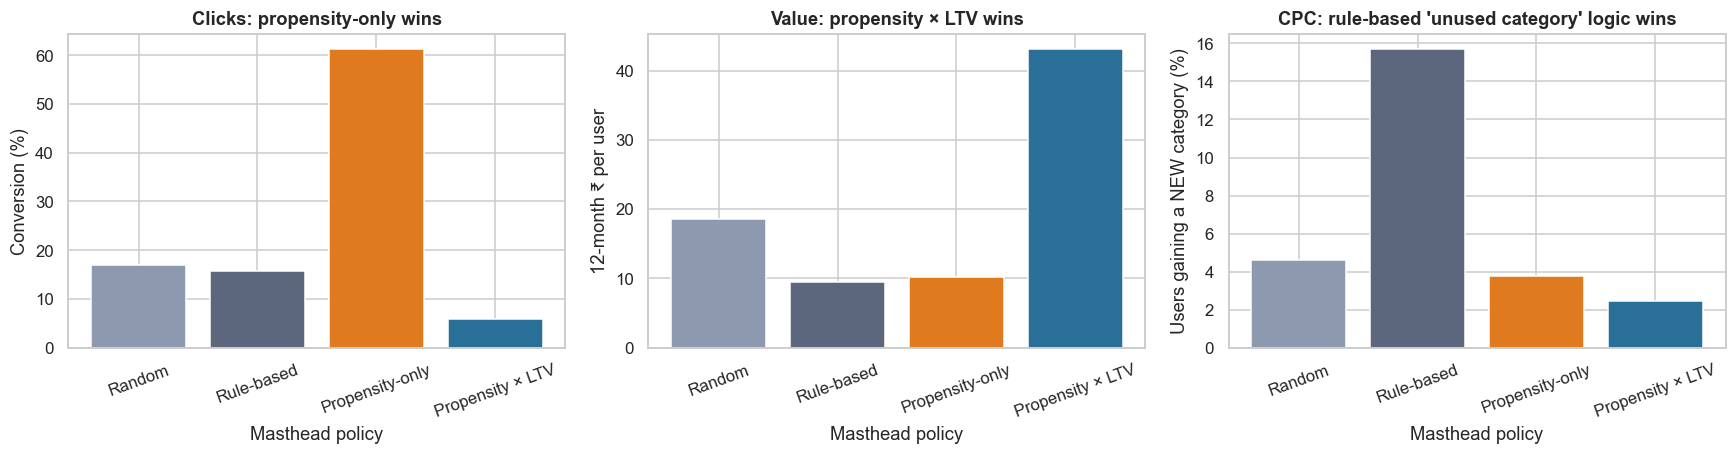

Masthead mix by policy (% of users):
shown             recharge  bill_pay  cc_bill    gold  travel  mutual_funds  insurance  personal_loan
arm                                                                                                  
Random             12.4000   12.3000  12.9000 12.4000 12.4000       12.8000    12.5000        12.5000
Rule-based         31.2000   30.0000  31.7000  5.8000  1.1000        0.2000     0.0000         0.0000
Propensity-only    43.7000   52.8000   1.6000  1.0000  0.6000        0.2000     0.2000         0.0000
Propensity × LTV       NaN       NaN      NaN     NaN  0.5000       38.4000    31.0000        30.1000


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
cols = ["#8d99ae", "#5c677d", "#e07a1f", "#2a6f97"]
for ax, col, lab in [(axes[0], "conversion", "Conversion (%)"), (axes[1], "revenue_per_user", "12-month ₹ per user"), (axes[2], "new_category_rate", "Users gaining a NEW category (%)")]:
    v = summ[col] * (100 if col != "revenue_per_user" else 1); ax.bar(summ.index, v, color=cols); ax.set_xlabel("Masthead policy"); ax.set_ylabel(lab)
    ax.tick_params(axis="x", rotation=20)
axes[0].set_title("Clicks: propensity-only wins"); axes[1].set_title("Value: propensity × LTV wins"); axes[2].set_title("CPC: rule-based 'unused category' logic wins")
plt.tight_layout(); plt.show()
mix = ab.groupby("arm").shown.value_counts(normalize=True).unstack().reindex(list(CHOICE))[CATS].mul(100).round(1)
print("Masthead mix by policy (% of users):"); print(mix.to_string())

**(c)/(f) Observation and takeaway:** - **Randomisation OK** (SRM p = 0.11). Every difference below is Holm-significant (p < 0.0001).
- **Conversion:** propensity-only **61.3%** ≫ random 16.9% > rule-based 15.7% ≫ **propensity × LTV 5.8%**.
- **Revenue per user (12-month ₹):** **propensity × LTV ₹43.2** (+₹33.7 vs rule, CI ₹31.6–35.9) ≫ random ₹18.6 > propensity-only ₹10.2 ≈ rule-based ₹9.5. **Even a random banner beats the rules on value**, because it shows high-LTV categories 3 times in 8.
- **New-category rate (CPC):** **rule-based 15.7%** is far ahead (it deliberately shows unused popular categories) vs random 4.6%, propensity-only 3.8% and propensity × LTV 2.5%.
- **Masthead mix:** propensity-only shows bill pay (53%) and recharge (44%) almost exclusively. Propensity × LTV shows mutual funds (38%), insurance (31%) and personal loans (30%). Rule-based spreads recharge, bill pay and card bill.
- **Reading:** each policy "wins" the metric it implicitly optimises. **The choice of objective is a business decision, not a modelling one**, which is why the PhonePe utility explicitly encodes value.

### 7.4 Heterogeneity by journey stage

Does the value-ranking advantage hold for new users as well as power users? We compute the revenue-per-user difference (propensity × LTV − rule-based) per stage, with bootstrap CIs, and Holm across the three stages.

In [13]:
het = []
for st in ["new (<30 days)", "active", "power"]:
    t_ = ab[(ab.arm == "Propensity × LTV") & (ab.stage == st)].rev.values; c_ = ab[(ab.arm == "Rule-based") & (ab.stage == st)].rev.values
    bs = [RNG_BOOT.choice(t_, len(t_)).mean() - RNG_BOOT.choice(c_, len(c_)).mean() for _ in range(1000)]
    het.append((st, len(t_), c_.mean(), t_.mean(), t_.mean() - c_.mean(), *np.percentile(bs, [2.5, 97.5]), stats.ttest_ind(t_, c_, equal_var=False).pvalue))
het = pd.DataFrame(het, columns=["journey stage", "users (treated)", "rule ₹/user", "p×LTV ₹/user", "difference", "CI low", "CI high", "Welch p"])
het["p_holm"] = multipletests(het["Welch p"], method="holm")[1]
het.round(3)

,journey stage,users (treated),rule ₹/user,p×LTV ₹/user,difference,CI low,CI high,Welch p,p_holm
0,new (<30 days),10107,9.3740,39.8120,30.4380,25.5160,35.6660,0.0000,0.0000
1,active,30015,9.6120,42.8150,33.2030,30.4200,35.7750,0.0000,0.0000
2,power,10201,9.0400,47.4620,38.4220,33.8630,43.2630,0.0000,0.0000


**Observation:** the value-ranking gain is large and significant in **every journey stage**: +₹30 per user for new users (CI ₹26–36), +₹33 for active and +₹38 for power users (all Holm p < 0.0001). It grows with engagement, but does not depend on it. New users also benefit, so there is no need for a separate rule-based path for them.

### 7.5 Power: how big must a revenue A/B test be?

Revenue per user is **extremely skewed**: most users earn ₹0, a few earn thousands. Its coefficient of variation (sd/mean) is large, which drives the sample size. Using the rule-based arm's mean and variance, we compute the users per arm needed to detect a **+10%** and a **+25%** revenue lift with 80% power (two-sided α = 0.05, normal approximation).

In [14]:
mu, sd = ctrl.rev.mean(), ctrl.rev.std()
pw = pd.DataFrame([(f"+{int(l * 100)}%", mu * l, int(np.ceil(2 * (1.96 + 0.84) ** 2 * sd ** 2 / (mu * l) ** 2))) for l in (0.10, 0.25, 0.50)],
                  columns=["revenue lift to detect", "₹/user", "users per arm (80% power)"])
print(f"Rule-based revenue/user: mean ₹{mu:.2f}, sd ₹{sd:.2f}, CV = {sd / mu:.1f}; share of users with ₹0 = {(ctrl.rev == 0).mean():.1%}")
pw

Rule-based revenue/user: mean ₹9.45, sd ₹34.12, CV = 3.6; share of users with ₹0 = 84.3%


,revenue lift to detect,₹/user,users per arm (80% power)
0,+10%,0.9453,20431
1,+25%,2.3632,3269
2,+50%,4.7264,818


**Observation:** revenue per user is extremely skewed: **84% of users earn ₹0** and the coefficient of variation is 3.6. Detecting a **+10%** revenue lift needs about **20,400 users per arm**, and +25% needs about 3,300. Our 50,000 per arm can detect lifts of roughly 6% and above. The large differences here (+357%) are therefore unambiguous. Refinements between close variants of the utility (e.g., two bonus settings) will need tens of thousands of users per arm, or CUPED with pre-period spend to cut the variance.

### 7.6 Sensitivity: what if the LTV estimates are wrong?

The value ranking sends many users to **personal loans**, the highest-LTV category, but loan LTV is the most uncertain number in the model (7.2). It must also be **risk-adjusted**: a loan that later defaults destroys value. We re-run the A/B digital twin with (a) the loan LTV halved in the *ranking* (a credit-loss haircut), and (b) a **concentration cap**, where no category may take more than 40% of mastheads (allocated greedily by utility). Outcomes are always scored with the true values.

In [15]:
def run_policy(L_rank, cap=None):
    U = Phat * L_rank
    if cap is None: ch = U.argmax(1)
    else:
        order = np.argsort(-U, axis=1); counts = np.zeros(8, int); ch = np.empty(len(U), int); lim = int(cap * len(U))
        for i in np.argsort(-U.max(1)):
            for j in order[i]:
                if counts[j] < lim: ch[i] = j; counts[j] += 1; break
    conv_ = (u < Ptrue[idx, ch]).astype(int); rev_ = np.where(conv_ == 1, Vtrue[idx, ch], 0)
    return conv_.mean(), rev_.mean(), ((conv_ == 1) & (USED[idx, ch] == 0)).mean(), np.bincount(ch, minlength=8).max() / len(ch), np.array(CATS)[np.bincount(ch, minlength=8).argmax()]
L_half = Lhat.copy(); L_half[:, CATS.index("personal_loan")] *= 0.5
sens = pd.DataFrame([("Propensity-only", *run_policy(np.ones_like(Lhat))), ("Propensity × LTV (as estimated)", *run_policy(Lhat)),
                     ("Propensity × LTV, loan LTV halved (risk-adjusted)", *run_policy(L_half)), ("Propensity × LTV, 40% category cap", *run_policy(Lhat, cap=0.40)),
                     ("Risk-adjusted + 40% cap", *run_policy(L_half, cap=0.40))],
                    columns=["policy (applied to all 200k users)", "conversion", "TRUE ₹/user", "new-category rate", "largest category share", "largest category"]).set_index("policy (applied to all 200k users)")
sens.round(4)

,conversion,TRUE ₹/user,new-category rate,largest category share,largest category
policy (applied to all 200k users),,,,,
Propensity-only,0.6125,10.1232,0.0380,0.5272,bill_pay
Propensity × LTV (as estimated),0.0580,44.9997,0.0256,0.3806,mutual_funds
"Propensity × LTV, loan LTV halved (risk-adjusted)",0.0587,42.5661,0.0272,0.4921,mutual_funds
"Propensity × LTV, 40% category cap",0.0580,44.9997,0.0256,0.3806,mutual_funds
Risk-adjusted + 40% cap,0.0744,43.0326,0.0306,0.4000,mutual_funds


### 7.7 Resolving the conflict: a guard-railed utility frontier

The pure value ranking wins on revenue but **fails the pre-registered engagement guardrail** (conversion below the random baseline) and adds few *new* categories. A common fix is to add a business value for outcomes that ₹ LTV misses:
- **Engagement bonus E:** every conversion is worth an extra ₹E (habit, data, ad inventory) → utility = P̂ × (LTV̂ + E).
- **CPC bonus B:** acquiring a *new* category is worth an extra ₹B (strategic value of a deeper relationship) → utility = P̂ × (LTV̂ + B·1{not yet used}).

We trace the frontier over a grid of E and B combined, utility = P̂ × (LTV̂ + E + B·1{new}) (true outcomes, all 200k users) and pick the **highest-revenue setting that keeps conversion ≥ the random baseline and new-category rate ≥ the random baseline**. Because the setting is chosen on the same simulated users, the winner must be confirmed in the next live A/B (D-20-05).

Guardrails: conversion ≥ 16.9% and new-category rate ≥ 4.6% (random arm), largest category ≤ 60%
Best guard-railed setting: [{'engagement bonus E ₹': 50, 'CPC bonus B ₹': 100, 'conversion': 0.2749, 'TRUE ₹/user': 36.5972785, 'new-category rate': 0.05459}]


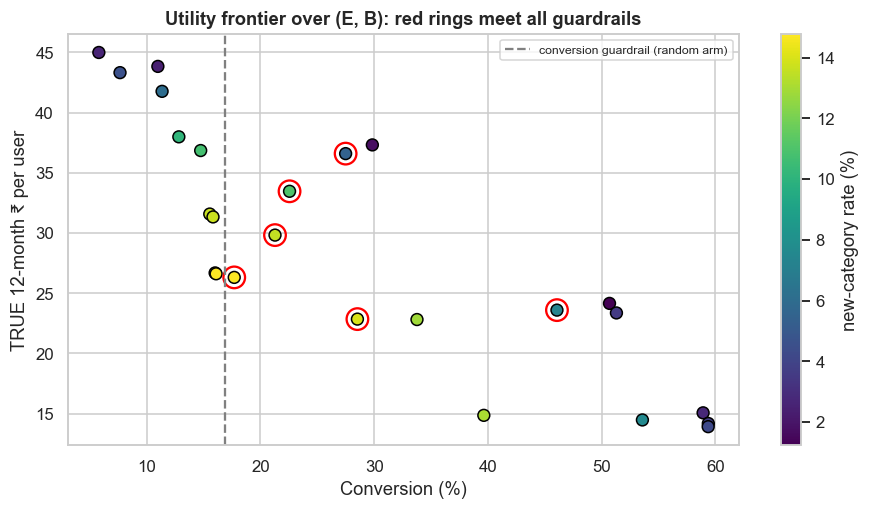

,engagement bonus E ₹,CPC bonus B ₹,conversion,TRUE ₹/user,new-category rate,largest category share,largest category,meets guardrails
0,0,0,0.0580,44.9997,0.0256,0.3806,mutual_funds,False
1,0,100,0.0766,43.3246,0.0460,0.3732,mutual_funds,False
2,0,200,0.1283,37.9917,0.1009,0.2929,mutual_funds,False
3,0,400,0.1555,31.5782,0.1363,0.3997,bill_pay,False
4,0,800,0.1602,26.6861,0.1477,0.4184,bill_pay,False
5,25,0,0.1099,43.8433,0.0240,0.3626,mutual_funds,False
6,25,100,0.1136,41.7711,0.0604,0.3453,mutual_funds,False
7,25,200,0.1475,36.8531,0.1075,0.3263,bill_pay,False
8,25,400,0.1583,31.3379,0.1371,0.4035,bill_pay,False
9,25,800,0.1610,26.6144,0.1478,0.4182,bill_pay,False


In [16]:
NEWM = (USED == 0).astype(float)
front = []
for E in (0, 25, 50, 100, 200):
    for B in (0, 100, 200, 400, 800):
        cv, rv, nc, mx, top = run_policy(Lhat + E + B * NEWM)
        front.append((E, B, cv, rv, nc, mx, top))
front = pd.DataFrame(front, columns=["engagement bonus E ₹", "CPC bonus B ₹", "conversion", "TRUE ₹/user", "new-category rate", "largest category share", "largest category"])
rand_conv, rand_new = summ.loc["Random", "conversion"], summ.loc["Random", "new_category_rate"]
front["meets guardrails"] = (front.conversion >= rand_conv) & (front["new-category rate"] >= rand_new) & (front["largest category share"] <= 0.60)
best = front[front["meets guardrails"]].sort_values("TRUE ₹/user", ascending=False).head(1)
print(f"Guardrails: conversion ≥ {rand_conv:.1%} and new-category rate ≥ {rand_new:.1%} (random arm), largest category ≤ 60%")
print("Best guard-railed setting:", best[["engagement bonus E ₹", "CPC bonus B ₹", "conversion", "TRUE ₹/user", "new-category rate"]].to_dict("records"))
fig, ax = plt.subplots(figsize=(8.5, 4.8))
sc = ax.scatter(front.conversion * 100, front["TRUE ₹/user"], c=front["new-category rate"] * 100, cmap="viridis", s=60, edgecolor="black")
plt.colorbar(sc, ax=ax, label="new-category rate (%)")
for _, r_ in front[front["meets guardrails"]].iterrows():
    ax.scatter(r_.conversion * 100, r_["TRUE ₹/user"], s=200, facecolors="none", edgecolors="red", lw=1.5)
ax.axvline(rand_conv * 100, ls="--", color="grey", label="conversion guardrail (random arm)")
ax.set_xlabel("Conversion (%)"); ax.set_ylabel("TRUE 12-month ₹ per user"); ax.set_title("Utility frontier over (E, B): red rings meet all guardrails"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
front.round(4)

**Takeaway:** - **No single bonus satisfies all guardrails.** An engagement bonus E lifts conversion but not new categories. A CPC bonus B lifts new categories but conversion stays below random.
- **Combining both works:** **E = ₹50, B = ₹100** gives conversion **27.5%** (above random 16.9% and rule 15.7%), **₹36.6 per user** (3.8× rule-based; 81% of the pure value ranking) and a 5.5% new-category rate. The highest-revenue setting meets every guardrail.
- If **CPC is a strategic priority**, **E = ₹50, B = ₹200** doubles new-category adoption to 11.0% (rule-based: 15.7%) for ₹33.5 per user. That is a −₹3 per user trade the business can choose explicitly.
- Larger bonuses (E ≥ ₹100) drift back to "show bill pay to everyone": high clicks, low value.
- **Caveat:** these settings were picked on the simulated population. Confirm the chosen one in a live A/B against pure value ranking and rule-based.

**Observation:** the value ranking is **robust to LTV error**. Halving the personal-loan LTV (a credit-loss haircut) lowers true value only from ₹45.0 to ₹42.6 per user (−5%), shifting mastheads towards mutual funds (largest share 38% → 49%). A 40% concentration cap does not bind (the largest category is already 38%). Combined risk-adjustment + cap gives ₹43.0. So the ranking does not collapse onto one product, and a 2× error in the most uncertain LTV costs only ~5% of the gain.

## 8. ML Section — does gradient boosting improve the per-category propensity models?

PhonePe documents "a multi-stage pipeline of non-linear models". We compare logistic regression with `HistGradientBoostingClassifier` (default settings; D-20-06) for the **acquisition** models (the ones that drive new-category value), on the same holdout split, using AUC.

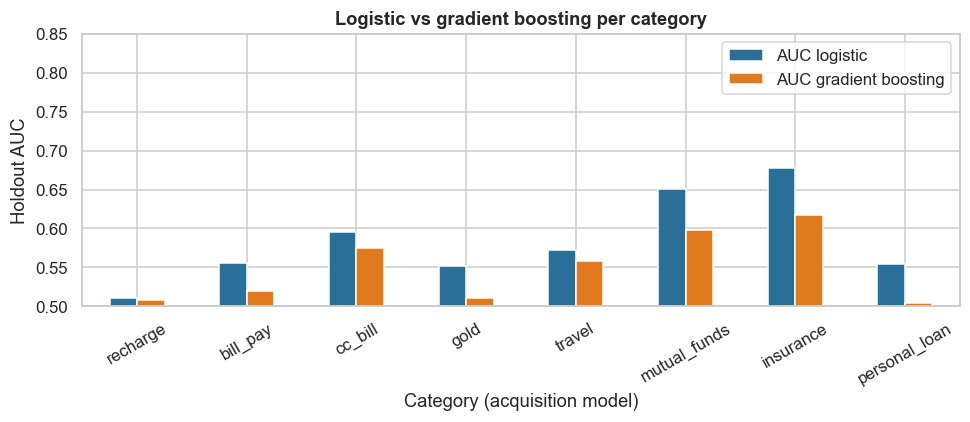

,holdout conversions,AUC logistic,AUC gradient boosting,Δ
category (acquisition),,,,
recharge,250,0.5110,0.5080,-0.0030
bill_pay,409,0.5550,0.5190,-0.0360
cc_bill,249,0.5960,0.5750,-0.0210
gold,159,0.5520,0.5110,-0.0410
travel,127,0.5720,0.5580,-0.0140
mutual_funds,102,0.6500,0.5980,-0.0530
insurance,66,0.6780,0.6170,-0.0610
personal_loan,50,0.5550,0.5050,-0.0500


In [17]:
cmp = []
for c in CATS:
    tr_ = tr_ex[(tr_ex.shown_category == c) & (tr_ex[f"used_{c}"] == 0)]; va_ = va_ex[(va_ex.shown_category == c) & (va_ex[f"used_{c}"] == 0)]
    gb = HistGradientBoostingClassifier(random_state=SEED).fit(feats(tr_), tr_.converted_7d)
    a_lr = roc_auc_score(va_.converted_7d, MODELS[(c, 0)].predict_proba(feats(va_))[:, 1]); a_gb = roc_auc_score(va_.converted_7d, gb.predict_proba(feats(va_))[:, 1])
    cmp.append((c, int(va_.converted_7d.sum()), a_lr, a_gb, a_gb - a_lr))
cmp = pd.DataFrame(cmp, columns=["category (acquisition)", "holdout conversions", "AUC logistic", "AUC gradient boosting", "Δ"]).set_index("category (acquisition)")
fig, ax = plt.subplots(figsize=(9, 4)); cmp[["AUC logistic", "AUC gradient boosting"]].plot(kind="bar", ax=ax, color=["#2a6f97", "#e07a1f"])
ax.set_ylim(0.5, 0.85); ax.set_xlabel("Category (acquisition model)"); ax.set_ylabel("Holdout AUC"); ax.set_title("Logistic vs gradient boosting per category")
ax.tick_params(axis="x", rotation=30); plt.tight_layout(); plt.show()
cmp.round(3)

**Takeaway:** gradient boosting is **worse than logistic in all 8 categories** (AUC Δ −0.003 to −0.061). Each acquisition model has only 50–409 holdout conversions and about 13k training rows with a few hundred events, too few for trees to beat a regularised linear model. PhonePe's "multi-stage pipeline of non-linear models" makes sense at 5,000+ features and hundreds of millions of users. At this scale, **logistic + calibration is the right tool**.

## 9. Business Translation — per crore users exposed per campaign cycle

**Logic:** the A/B revenue per user (12-month margin attributed to the masthead conversion) × 1 crore users exposed in a cycle (e.g., a week's masthead). We report the incremental value of each policy vs rule-based, with bootstrap CIs scaled up, and for the risk-adjusted capped policy from 7.6. Assumptions (D-20-07): LTV is 12-month margin; repeat use counts 25%; one masthead impression per user per cycle.

In [18]:
SCALE = 1e7
inc = tests[tests.metric == "revenue ₹/user"].set_index("arm")[["difference vs rule-based", "CI low", "CI high"]] * SCALE / 1e7
inc.columns = ["₹ crore per crore users vs rule-based", "CI low", "CI high"]
rule_true = (Ptrue[idx, CHOICE["Rule-based"]] * Vtrue[idx, CHOICE["Rule-based"]]).mean()
extra = pd.DataFrame({"TRUE ₹/user": sens["TRUE ₹/user"], "₹ crore per crore users vs rule-based (true)": (sens["TRUE ₹/user"] - rule_true) * SCALE / 1e7})
print(f"Rule-based true value: ₹{rule_true:.2f} per user")
display(inc.round(2)); extra.round(2)

Rule-based true value: ₹9.55 per user


,₹ crore per crore users vs rule-based,CI low,CI high
arm,,,
Random,9.1700,7.8100,10.6600
Propensity-only,0.7100,0.4000,1.0200
Propensity × LTV,33.7000,31.6000,35.8900


,TRUE ₹/user,₹ crore per crore users vs rule-based (true)
policy (applied to all 200k users),,
Propensity-only,10.1200,0.5700
Propensity × LTV (as estimated),45.0000,35.4500
"Propensity × LTV, loan LTV halved (risk-adjusted)",42.5700,33.0100
"Propensity × LTV, 40% category cap",45.0000,35.4500
Risk-adjusted + 40% cap,43.0300,33.4800


**Business reading:** - **Per crore users exposed per masthead cycle (12-month margin):** pure propensity × LTV adds **≈ ₹33.7 crore** vs rule-based (CI ₹31.6–35.9 crore). The **guard-railed version (E = ₹50, B = ₹100) adds ≈ ₹27 crore** (true value ₹36.6 vs ₹9.55 per user). Risk-adjusted + capped value ranking adds ≈ ₹33.5 crore.
- **Propensity-only** adds just **≈ ₹0.6–0.7 crore** despite 4× the conversions. Clicks are not money.
- **Even a random masthead adds ≈ ₹9 crore** over the current rules. The manual "popular unused category" rule leaves a lot of value on the table.
- These ₹ figures are 12-month margins from synthetic LTVs. The ranking of policies, not the absolute crores, is what transfers.

## 10. Recommendation and Decision

**Decision against the pre-registered rule:** pure propensity × LTV has the highest revenue (CI vs rule excludes 0 ✅) but fails the conversion guardrail (❌ 5.8% < 16.9%). **Adopt the guard-railed utility (E = ₹50, B = ₹100)**, which meets every guardrail and keeps ≈ 80% of the value.

**I recommend:**
1. **Replace manual masthead curation with per-user ranking** by utility = P̂ × (risk-adjusted LTV + ₹50 + ₹100 × new-category). Keep separate acquisition and repeat models per category, re-fitted monthly and **calibration-checked** each time.
2. **Validate live:** a 4-arm A/B (rule-based, pure value, guard-railed value, random), ≥ 20k users per arm, 4 weeks, one pre-registered read, then a 5% permanent random-exploration slice.
3. **Lending and insurance suitability:** apply eligibility filters (pre-approved loans only; age/need filters for insurance) *before* ranking, and use LTV net of expected credit loss.
4. **Let the business own the bonus weights (E, B):** they encode strategy (engagement vs depth vs margin). Review them quarterly with the frontier chart.

**KPIs:** 12-month revenue per exposed user (vs control); conversion rate; new-category adoption (CPC); masthead mix concentration; calibration error per model; complaints/opt-outs on lending and insurance banners; 90-day retention of acquired users.

## 11. Risks, Limitations and Next Steps

- **Synthetic data:** propensities and LTVs are ours. PhonePe published no impact numbers, so the *size* of gains here is illustrative. The *direction* (value ranking beats click ranking on revenue and CPC) follows from the utility logic.
- **LTV is the weakest input:** it is estimated from few converters in high-value categories, and **lending LTV must be net of credit losses** (and of regulatory constraints on loan promotion). Mis-specified LTV can concentrate the masthead on one product. Use risk-adjusted LTV, CIs, and caps.
- **Short-term vs long-term:** we score 12-month value but measure the experiment on 7-day conversions. Long-term effects (users who ignore irrelevant banners, banner blindness) need a holdout tracked for months.
- **Fairness and suitability:** showing loans and insurance more to some users raises suitability questions (RBI and IRDAI fair-practice expectations). Product teams must define eligibility filters *before* ranking.
- **Next steps:** (1) an exploration share (e.g., 5% random mastheads) to keep training data unbiased; (2) a contextual bandit for the masthead slot; (3) multi-slot ranking (diversity across the home screen); (4) CUPED with pre-period spend to cut the large revenue sample sizes in 7.5.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Utility (ranking score) | U(u, c) = P̂(convert \| u, c) × LTV̂(c, repeat status) |
| Calibration-in-the-large | mean P̂ vs observed rate (Wilson CI) |
| Revenue difference CI | bootstrap percentile of mean_T − mean_C |
| Sample size (means) | n = 2(z₁₋α/₂ + z₁₋β)² σ² / δ² per arm |
| CPC uplift | share of users acquiring a category they did not use before |

| Term | Meaning |
|---|---|
| Masthead | The top banner on the app's home screen. |
| Propensity | Probability a user transacts in a category if shown it. |
| LTV | Lifetime (here 12-month) margin from a user's activity in a category. |
| Acquisition vs repeat model | First-time use of a category vs continued use. |
| Categories per customer (CPC) | How many different products a user uses; a key super-app health metric. |
| Exploration log | Data where items were shown at random, so models learn without bias. |
| Digital twin | A simulation that lets us test policies before going live. |